# Tutorial 2 · Microglia in Alzheimer's disease
Two amyloid models (paper Fig. 5):
**A.** Xenium, TgCRND8 at 2.5, 5.7, 17.9 months and wild type at 2.5, 5.7, 13.4 months: which homeostatic microglia become DAM.
**B.** STARmap PLUS, TauPS2APP and control at 8 and 13 months (2 mice each): DAM that return to the homeostatic state, and the
signals that keep them DAM. Settings as in the paper: received signals pre-computed with CytoSignal (`obsm['cytosignal']`,
ligand-receptor pairs) and one microglia state space for all sections of a study.

In [1]:
import anndata as ad, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import nichefate as nf
DATA = "../tutorial_data/"
MG = ["homeostatic", "DAM"]; MG3 = MG + ["BAM-like"]
COL = {"homeostatic": "#3a6db5", "DAM": "#c8553d"}

## A · Xenium: homeostatic → DAM

347 shared genes, 13 ligand-receptor pairs, 13 signals (pair)


C:\Users\au827475\Dropbox\Niche-FATE\nichefate\_gnn.py:14: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  At = torch.sparse_coo_tensor(np.vstack([A.row, A.col]), A.data.astype(np.float32), A.shape, device=device).coalesce()


niche computed for 6 sections: [53328, 58026, 59392, 58167, 58583, 58597] cells


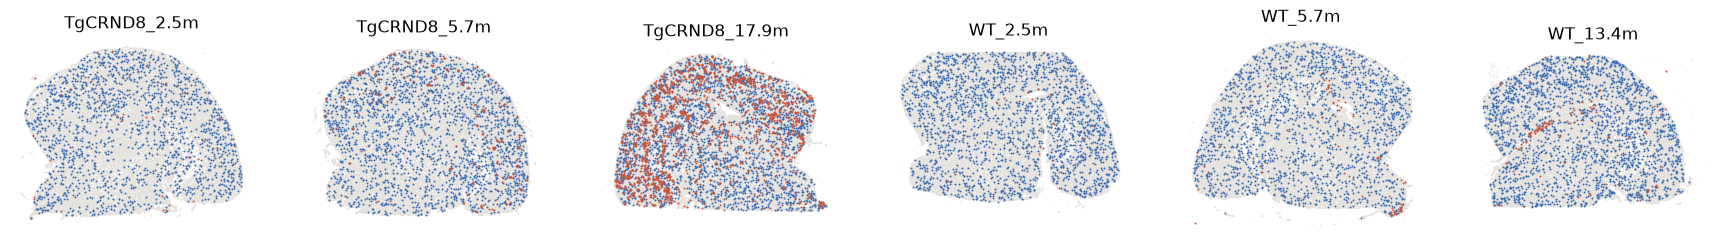

In [2]:
TG = ["TgCRND8_2.5m", "TgCRND8_5.7m", "TgCRND8_17.9m"]; WT = ["WT_2.5m", "WT_5.7m", "WT_13.4m"]
tg = [ad.read_h5ad(DATA + f"ad_{s}.h5ad") for s in TG]; wt = [ad.read_h5ad(DATA + f"ad_{s}.h5ad") for s in WT]
allX = tg + wt
nf.compute_niche(allX, level="pair", signals=[pd.DataFrame(x.obsm["cytosignal"], index=x.obs_names, columns=x.uns["cytosignal_names"]) for x in allX],
                 target_sum=100, n_sub=150_000)
fig, ax = plt.subplots(1, 6, figsize=(22, 4))
for a, s, x in zip(ax, TG + WT, tg + wt):
    nf.pl.groups_map(x, "state", ax=a, s=2, order=MG, colors=COL); a.set_title(s); a.get_legend().remove()
plt.show()

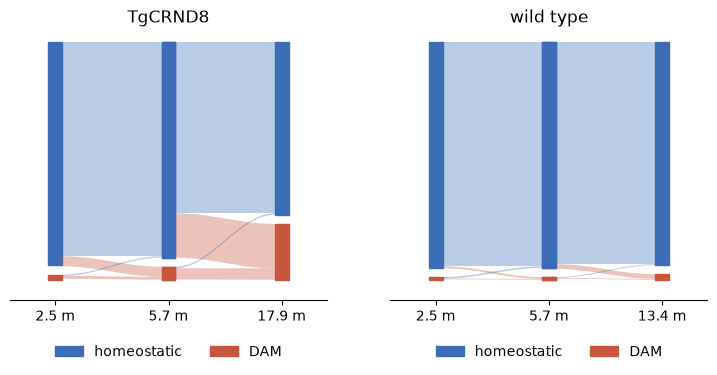

,TgCRND8,wild type
early,0.045,0.009
late,0.204,0.020


In [3]:
kw = dict(groupby="state", cells1=MG3, cells2=MG3, pca_sections=allX, pca_cells=[x.obs.state.isin(MG3).values for x in allX], scale_signals=False)
res_tg = [nf.match(tg[i], tg[i + 1], **kw) for i in range(2)]
res_wt = [nf.match(wt[i], wt[i + 1], **kw) for i in range(2)]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
nf.pl.sankey(res_tg, MG, labels=["2.5 m", "5.7 m", "17.9 m"], colors=COL, ax=ax[0]); ax[0].set_title("TgCRND8")
nf.pl.sankey(res_wt, MG, labels=["2.5 m", "5.7 m", "13.4 m"], colors=COL, ax=ax[1]); ax[1].set_title("wild type"); plt.show()
pd.DataFrame({"TgCRND8": [r.transitions.loc["homeostatic", "DAM"] for r in res_tg], "wild type": [r.transitions.loc["homeostatic", "DAM"] for r in res_wt]},
             index=["early", "late"]).round(3)

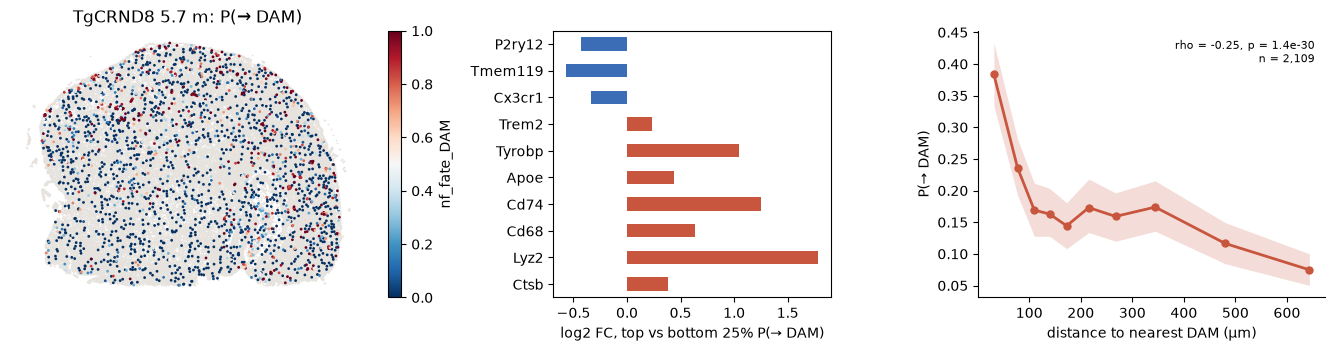

In [4]:
x = tg[1]; p = nf.fate(res_tg[1], "DAM", among=MG)
h = x.obs.state.values[res_tg[1].idx1] == "homeostatic"; ph = p[h]
genes = ["P2ry12", "Tmem119", "Cx3cr1", "Trem2", "Tyrobp", "Apoe", "Cd74", "Cd68", "Lyz2", "Ctsb"]
L = pd.DataFrame(x[ph.index, genes].layers["nf_lognorm"].toarray(), index=ph.index, columns=genes)
top, bot = ph >= ph.quantile(0.75), ph <= ph.quantile(0.25)
lfc = np.log2((L[top].mean() + 0.01) / (L[bot].mean() + 0.01))
dDAM = cKDTree(x.obsm["spatial"][x.obs.state.values == "DAM"]).query(x[ph.index].obsm["spatial"])[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.3, 0.8, 1]))
nf.pl.fate_map(x, "nf_fate_DAM", ax=ax[0], s=4, title="TgCRND8 5.7 m: P(→ DAM)")
lfc[::-1].plot.barh(ax=ax[1], color=[COL["DAM"] if v > 0 else COL["homeostatic"] for v in lfc[::-1]]); ax[1].set_xlabel("log2 FC, top vs bottom 25% P(→ DAM)")
nf.pl.binned(dDAM, ph.values, n_bins=10, ax=ax[2], xlabel="distance to nearest DAM (µm)", ylabel="P(→ DAM)")
plt.tight_layout(); plt.show()

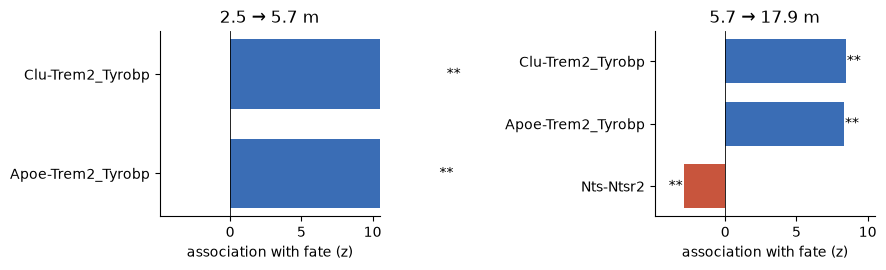

,signal,r,z,p,q,stable,detect
0,Clu-Trem2_Tyrobp,0.1861,8.4602,0.0005,0.0017,True,0.3882
1,Apoe-Trem2_Tyrobp,0.1830,8.3292,0.0005,0.0017,True,0.3882
2,Cdh6-Cdh6,0.0068,0.2747,0.7521,0.8151,False,0.2232
3,Pecam1-Pecam1,0.0051,0.2187,0.8151,0.8151,True,0.6534
4,Cdh4-Cdh4,-0.0355,-1.5499,0.1249,0.1749,True,0.3078
5,Aldh1a2-Rorb,-0.0439,-1.8971,0.0615,0.1076,False,0.3320
6,Nts-Ntsr2,-0.0637,-2.9071,0.0030,0.0070,True,0.1483


In [5]:
for x in tg:
    x.obs["neuron"] = np.where(x.obs.cell_type.isin(["ExN", "InN"]), "neuron", "other")
dx = [nf.drivers(r, nf.fate(r, "DAM", among=MG), cells=["homeostatic"], composition_key="neuron", celltype_key="cell_type", min_detect=0.10, n_perm=2000) for r in res_tg]
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8), sharex=True)
for a, d, t in zip(ax, dx, ["2.5 → 5.7 m", "5.7 → 17.9 m"]):
    nf.pl.drivers(d, ax=a); a.set_title(t)
plt.tight_layout(); plt.show()
dx[1].round(4)

## B · STARmap PLUS: DAM that revert

2766 shared genes, 439 ligand-receptor pairs, 127 signals (pathway)


niche computed for 8 sections: [8186, 10372, 8202, 9634, 8506, 8034, 9803, 9428] cells


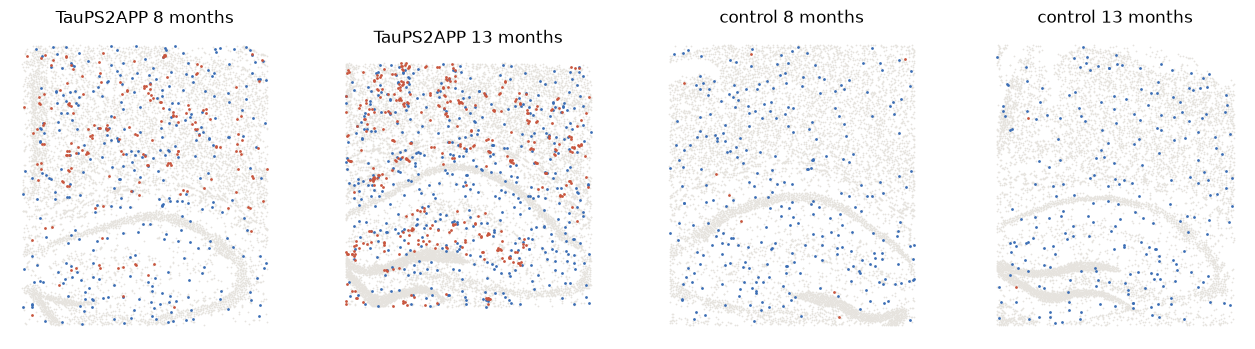

In [6]:
S = {(g, r, t): ad.read_h5ad(DATA + f"starmap_{g}_r{r}_{t}m.h5ad") for g in ("TauPS2APP", "control") for r in (1, 2) for t in (8, 13)}
allS = list(S.values())
nf.compute_niche(allS, signals=[pd.DataFrame(x.obsm["cytosignal"].astype(float), index=x.obs_names, columns=x.uns["cytosignal_pairs"]) for x in allS])
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, k in zip(ax, [("TauPS2APP", 1, 8), ("TauPS2APP", 1, 13), ("control", 1, 8), ("control", 1, 13)]):
    nf.pl.groups_map(S[k], "state", ax=a, s=4, order=MG, colors=COL); a.set_title(f"{k[0]} {k[2]} months"); a.get_legend().remove()
plt.show()

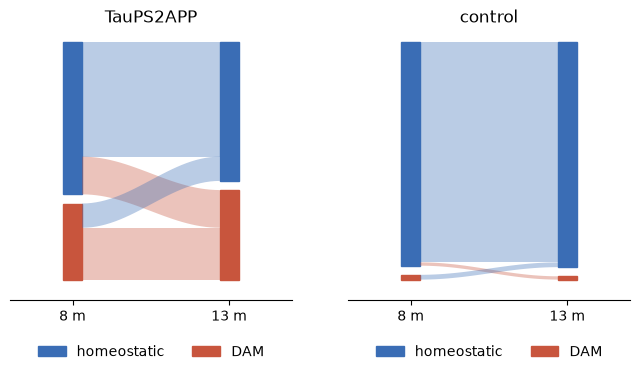

,homeostatic,DAM
homeostatic,0.752,0.248
DAM,0.318,0.682


In [7]:
R = {(g, a, b): nf.match(S[g, a, 8], S[g, b, 13], groupby="state", cells1=MG, cells2=MG, w_niche=0, pca_sections=allS, scale_signals=False)
     for g in ("TauPS2APP", "control") for a in (1, 2) for b in (1, 2)}
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, g in zip(ax, ("TauPS2APP", "control")):
    nf.pl.sankey([[R[g, i, j] for i in (1, 2) for j in (1, 2)]], MG, labels=["8 m", "13 m"], colors=COL, ax=a); a.set_title(g)
plt.show()
(sum(R["TauPS2APP", i, j].transitions.loc[MG, MG] for i in (1, 2) for j in (1, 2)) / 4).round(3)

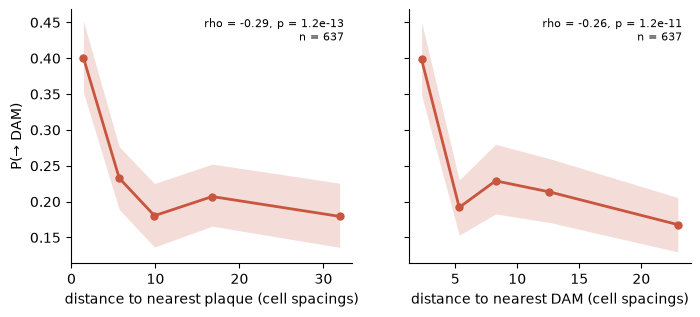

In [8]:
def avg(a, target):
    return (nf.fate(R["TauPS2APP", a, 1], target, among=MG) + nf.fate(R["TauPS2APP", a, 2], target, among=MG)) / 2
pdam = {a: avg(a, "DAM") for a in (1, 2)}; prev = {a: avg(a, "homeostatic") for a in (1, 2)}
hp, dp, dd = [], [], []
for a in (1, 2):
    x = S["TauPS2APP", a, 8]; o = x.obs.loc[pdam[a].index]; h = (o.state == "homeostatic").values
    hp.append(pdam[a][h].values); dp.append(o.plaque_dist.values[h])
    dd.append(cKDTree(x.obsm["nf_loc"][x.obs.state.values == "DAM"]).query(x[o.index[h]].obsm["nf_loc"])[0])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.3), sharey=True)
nf.pl.binned(np.concatenate(dp), np.concatenate(hp), ax=ax[0], xlabel="distance to nearest plaque (cell spacings)", ylabel="P(→ DAM)")
nf.pl.binned(np.concatenate(dd), np.concatenate(hp), ax=ax[1], xlabel="distance to nearest DAM (cell spacings)"); plt.show()

In [9]:
grp = dict(zip(allS[0].uns["cytosignal_pairs"], allS[0].uns["cytosignal_pathway"]))
dr = nf.drivers([R["TauPS2APP", 1, 1], R["TauPS2APP", 2, 1]], [prev[1], prev[2]], cells=["DAM"], composition_key="major",
                celltype_key="subclass", min_detect=0.05, n_perm=2000, signal_groups=grp)
print(dr.attrs["n_cells"], "DAM-like cells,", len(dr), "pathways tested")
dr[dr.p < 0.05].round(4)

319 DAM-like cells, 66 pathways tested


,signal,r,z,p,q,z_1,z_2,stable,detect
61,LGALS3,-0.1234,-2.0961,0.0361,0.4537,-0.9558,-2.0085,False,0.0599
62,CLDN,-0.1339,-2.1691,0.0301,0.4537,-0.3404,-2.7271,True,0.0581
63,ncWNT,-0.1428,-2.4130,0.0158,0.3480,-0.8205,-2.5920,True,0.0688
64,TBXAS1,-0.1653,-2.9015,0.0037,0.1226,-2.0488,-2.0546,True,0.0547
65,CCL,-0.2007,-3.5503,0.0004,0.0254,-2.3022,-2.7187,True,0.1047


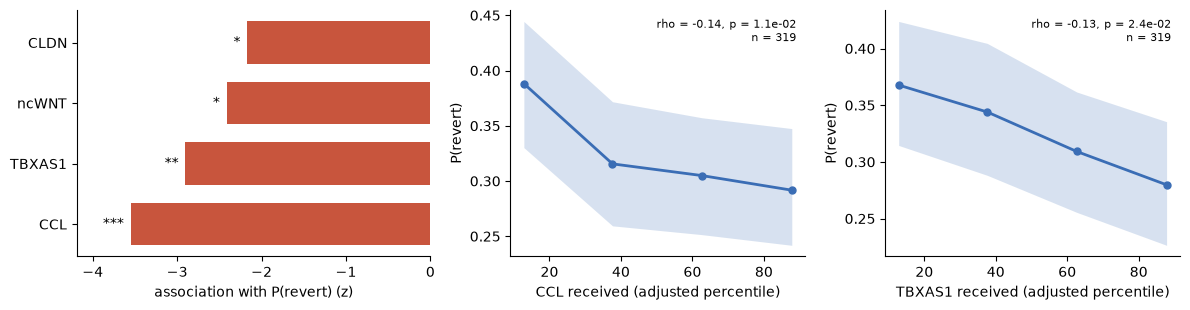

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
nf.pl.drivers(dr, ax=ax[0], by="p", color=COL["homeostatic"], neg_color=COL["DAM"]); ax[0].set_xlabel("association with P(revert) (z)")
y = pd.concat([prev[1], prev[2]])
for a, s in zip(ax[1:], ["CCL", "TBXAS1"]):
    v = pd.concat([R["TauPS2APP", i, 1].adjusted[s].rank(pct=True) * 100 for i in (1, 2)])
    nf.pl.binned(v.values, y[v.index].values, n_bins=4, ax=a, color=COL["homeostatic"], xlabel=f"{s} received (adjusted percentile)", ylabel="P(revert)")
plt.tight_layout(); plt.show()